# Functions and array shapes for repeated trajectories

How can one checked calculation work for many trials without mixing time and coordinate axes?

Proposed 2027; calendar dates pending.


# From one interval to a batch
Predict the vector and magnitude for a move from (0,0) to (1,1) mm in 2 s. Implement the function below before inspecting the batch.

In [1]:
import numpy as np
def interval_velocity(start, end, elapsed_s):
    if not np.isfinite(elapsed_s) or elapsed_s <= 0:
        raise ValueError("Elapsed time must be finite and positive.")
    return (np.asarray(end, dtype=float) - np.asarray(start, dtype=float)) / elapsed_s
v = interval_velocity([0, 0], [1, 1], 2)
print("Velocity (mm/s):", v, "magnitude:", np.linalg.norm(v))

Velocity (mm/s): [0.5 0.5] magnitude: 0.7071067811865476


Predict the three shapes: positions, interval velocities and magnitudes. The supplied batch helper validates the complete input contract; the short function above is deliberately limited to valid two-component examples.

In [2]:
from demo import trajectories, velocities, rotation, screen_speeds, run
times, positions = trajectories()
v = velocities(times, positions)
magnitude = np.linalg.norm(v, axis=2)
print(positions.shape, v.shape, magnitude.shape)
print(screen_speeds(magnitude))

(3, 5, 2) (3, 4, 2) (3, 4)
[[False False False False]
 [False False False False]
 [False False  True False]]


Now trace the loop for trial 1. Complete or modify the arithmetic and compare it with the vectorized row.

In [3]:
loop_row = []
for i in range(len(times) - 1):
    delta = positions[0, i + 1] - positions[0, i]
    duration = times[i + 1] - times[i]
    loop_row.append(np.linalg.norm(delta) / duration)
assert np.allclose(loop_row, magnitude[0])
print("Loop row:", loop_row)

Loop row: [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(1.0)]


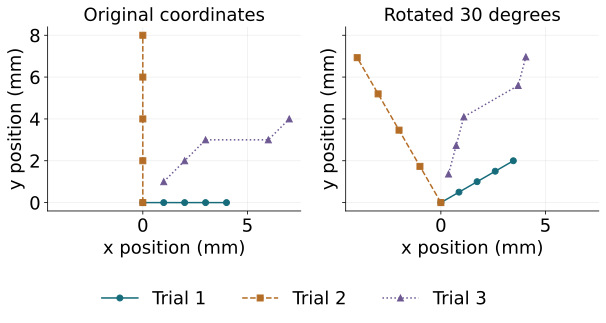

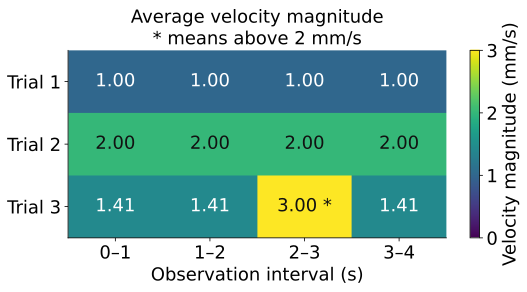

In [4]:
from IPython.display import SVG, display
report = run()
display(SVG(filename="trajectory-rotation.svg"))
display(SVG(filename="speed-shape-map.svg"))

Predict the effect of doubling all observation times. Then change the rotation angle to another finite value. These are guided invariance checks, not an inference about the path between samples.

In [5]:
slower = np.linalg.norm(velocities(2 * times, positions), axis=2)
assert np.allclose(slower, magnitude / 2)
angle_degrees = 45
R = rotation(angle_degrees)
changed = positions @ R.T
assert np.allclose(np.linalg.norm(velocities(times, changed), axis=2), magnitude)
print("Both predicted checks passed.")

Both predicted checks passed.


Display the changed geometry rather than using a hidden plotting backend. Explain why the components moved but magnitudes did not.

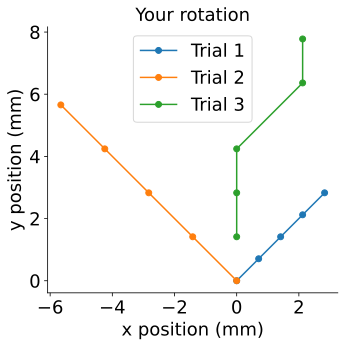

In [6]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots()
for trial in range(len(changed)):
    ax.plot(changed[trial, :, 0], changed[trial, :, 1], "o-", label=f"Trial {trial+1}")
ax.set(xlabel="x position (mm)", ylabel="y position (mm)", aspect="equal", title="Your rotation")
ax.legend()
fig.savefig("edited-rotation.svg", bbox_inches="tight")
plt.close(fig)
display(SVG(filename="edited-rotation.svg"))

Restart and run in order. State the axes of every result and one input case that should raise an error.